# 01. Data, leakage-controlled splits and pHash reuse detection
Sources: D-Fire (CC0) and an HPWREN FIgLib pilot (CC BY-NC 4.0). Everything here is read from `docs/data/*.json`, produced by `scripts/build_dfire_manifest.py` and `scripts/bench_phash.py`.

In [1]:
import json, os, sys, pathlib
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
ROOT = pathlib.Path(os.getcwd()).resolve().parent if pathlib.Path(os.getcwd()).name == "notebooks" else pathlib.Path(os.getcwd())
sys.path.insert(0, str(ROOT / "src"))
J = lambda n: json.load(open(ROOT / "docs" / "data" / n))
COL = {"blue": "#2f6fb3", "orange": "#d9822b", "grey": "#8a8f98", "green": "#3a9a6e", "red": "#c24d4d"}

## Partition sizes and label balance
Clusters touching the fixed-camera AoF source are held out whole (`xsrc_aof`); everything else is cluster-split.

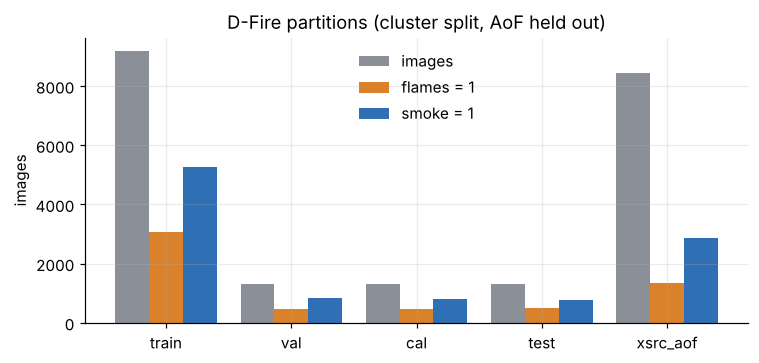

{'n_images': 21527, 'n_clusters': 10670, 'largest_cluster': 8428, 'clusters_spanning_original_splits': 414, 'images_in_those_clusters': 10997}


In [2]:
s = J("dfire_split_report.json"); P = s["per_partition_xsrc"]; names = list(P)
x = np.arange(len(names)); w = .27
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(x - w, [P[n]["n"] for n in names], w, label="images", color=COL["grey"])
ax.bar(x, [P[n]["flames"] for n in names], w, label="flames = 1", color=COL["orange"])
ax.bar(x + w, [P[n]["smoke"] for n in names], w, label="smoke = 1", color=COL["blue"])
ax.set_xticks(x, names); ax.set_ylabel("images"); ax.legend(frameon=False); ax.set_title("D-Fire partitions (cluster split, AoF held out)")
plt.tight_layout(); plt.show()
print({k: s[k] for k in ("n_images", "n_clusters", "largest_cluster", "clusters_spanning_original_splits", "images_in_those_clusters")})

## The Kaggle splits leak
414 near-duplicate clusters (about 11k images) span more than one of Kaggle's own train/val/test folders, so they are not used.

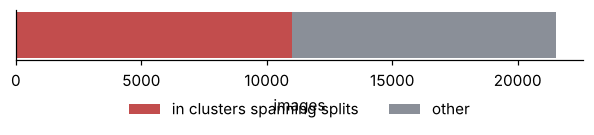

In [3]:
leak, tot = s["images_in_those_clusters"], s["n_images"]
fig, ax = plt.subplots(figsize=(5.5, 1.8)); ax.barh([0], [leak], color=COL["red"], label="in clusters spanning splits"); ax.barh([0], [tot - leak], left=[leak], color=COL["grey"], label="other")
ax.set_yticks([]); ax.set_xlabel("images"); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.5), ncol=2); ax.grid(False); plt.tight_layout(); plt.show()

## pHash reuse detection
Each query is a transformed copy of an indexed image; match = Hamming distance <= 6.

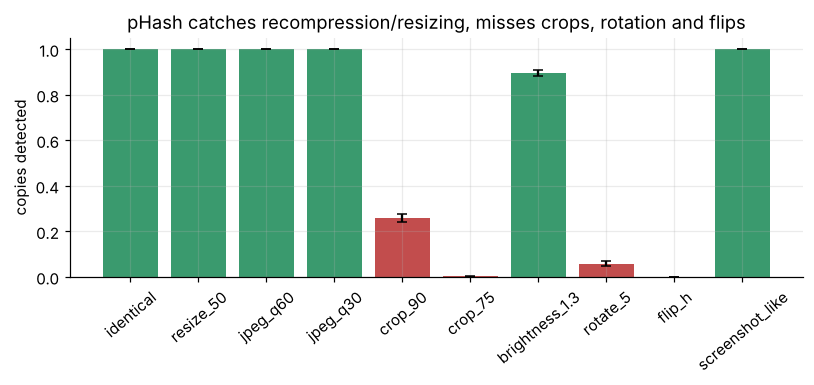

In [4]:
b = J("phash_bench.json"); T = b["transforms"]; k = list(T)
r = np.array([T[i]["detect_rate"] for i in k]); lo = r - np.array([T[i]["ci95"][0] for i in k]); hi = np.array([T[i]["ci95"][1] for i in k]) - r
fig, ax = plt.subplots(figsize=(7.5, 3.6)); ax.bar(k, r, yerr=[lo, hi], color=[COL["green"] if v > .85 else COL["red"] if v < .3 else COL["orange"] for v in r], capsize=3)
ax.set_ylabel("copies detected"); ax.set_ylim(0, 1.05); ax.tick_params(axis="x", rotation=40); ax.set_title("pHash catches recompression/resizing, misses crops, rotation and flips")
plt.tight_layout(); plt.show()

**Reading:** crops, rotations and flips need the CLIP-embedding nearest-neighbour layer. Flips are also covered by hashing the mirrored image (`phash_variants`).

## FIgLib frames inside D-Fire
Top row: HPWREN FIgLib frames. Bottom row: the closest D-Fire images (Hamming <= 2). A 'train D-Fire, test FIgLib' test would leak.

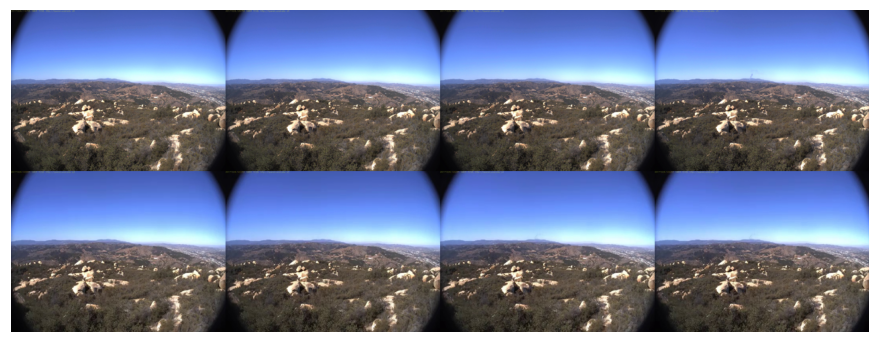

81 of 531 FIgLib pilot images match a D-Fire image at distance <= 2


In [5]:
from PIL import Image
plt.figure(figsize=(11, 3.8)); plt.imshow(Image.open(ROOT / "docs/figures/dfire_figlib_overlap.png")); plt.axis("off"); plt.show()
x = b["cross_dataset_false_match_figlib_vs_dfire"]; print(f"{x['figlib_imgs_with_match_le_2']} of {x['figlib_images']} FIgLib pilot images match a D-Fire image at distance <= 2")